# 01 — Project overview & raw data audit

**Objective.** Establish the prediction contract, inventory the immutable source files, and
document every structural integrity finding *before* any cleaning or modelling.

**Method.** Load the three raw CSVs, profile schema/missingness/cardinality, and probe the
`N_Days` target relationship that VISION §10 flags as a leakage risk. No row is modified here.

**Deliverables.** Schema tables, an integrity JSON, class/N_Days figures and a written decision log.

In [1]:
import sys, warnings, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
for p in (ROOT, ROOT / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from src.cirrhosis import config, paths, data, features, preprocessing, models, evaluation, inference

paths.ensure_dirs()
for sub in ("data_quality", "cleaning", "experiments", "final_evaluation"):
    (paths.REPORTS_DIR / sub).mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="Blues_d")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "figure.autolayout": True})
SEED = config.RANDOM_SEED
print("Environment ready; seed =", SEED)

Environment ready; seed = 42


In [2]:
train, test, submission = data.load_raw()
print("train", train.shape, "| test", test.shape, "| sample_submission", submission.shape)
print("Target classes present:", sorted(train[config.TARGET].unique()))
display(train.head())

train (15000, 20) | test (10000, 19) | sample_submission (10000, 4)
Target classes present: ['C', 'CL', 'D', 'Y']


,id,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
0,0,2178.0,D-penicillamine,16374.0,F,N,N,N,N,0.5,263.0,3.20,43.0,1110.0,106.95,67.0,430.0,9.6,3.0,C
1,1,2644.0,D-penicillamine,17774.0,F,N,N,N,N,0.8,280.0,3.60,22.0,678.0,62.00,80.0,427.0,13.0,3.0,C
2,2,3069.0,Placebo,17844.0,F,N,N,N,N,1.1,408.0,4.40,54.0,2108.0,142.60,137.0,203.0,10.6,3.0,C
3,3,2216.0,Placebo,19221.0,F,N,Y,Y,N,0.8,252.0,3.70,36.0,843.0,55.80,56.0,336.0,9.6,4.0,C
4,4,2256.0,Placebo,21600.0,F,N,N,N,N,4.7,348.0,3.06,464.0,961.0,120.90,146.0,298.0,11.0,2.0,D


In [3]:
schema_train = data.schema_summary(train)
schema_test = data.schema_summary(test)
schema_train.to_csv(paths.REPORTS_DIR / "data_quality" / "schema_train.csv", index=False)
schema_test.to_csv(paths.REPORTS_DIR / "data_quality" / "schema_test.csv", index=False)
display(schema_train)

,column,dtype,non_null,missing,missing_pct,n_unique,example
0,id,int64,15000,0,0.00,15000,0
1,N_Days,float64,15000,0,0.00,553,2178.0
2,Drug,str,8494,6506,43.37,2,D-penicillamine
3,Age,float64,15000,0,0.00,391,16374.0
4,Sex,str,15000,0,0.00,2,F
5,Ascites,str,8502,6498,43.32,2,N
6,Hepatomegaly,str,8492,6508,43.39,2,N
7,Spiders,str,8491,6509,43.39,2,N
8,Edema,str,15000,0,0.00,3,N
9,Bilirubin,float64,15000,0,0.00,117,0.5


In [4]:
audit = data.integrity_audit(train, test)
with (paths.REPORTS_DIR / "data_quality" / "integrity_audit.json").open("w") as fh:
    json.dump(audit, fh, indent=2, default=str)
for key, value in audit.items():
    print(f"{key}: {value}")

train_rows: 15000
test_rows: 10000
duplicate_train_rows: 0
id_overlap: 0
invalid_label_rows: [13789]
invalid_label_count: 1
age_below_18: 12
age_above_100: 2
n_days_median_by_status: {'C': 2170.0, 'CL': 1447.0, 'D': 1067.0, 'Y': 4127.0}
class_counts: {'C': 10053, 'D': 4565, 'CL': 381, 'Y': 1}


,median_N_Days
C,2170.0
CL,1447.0
D,1067.0
Y,4127.0


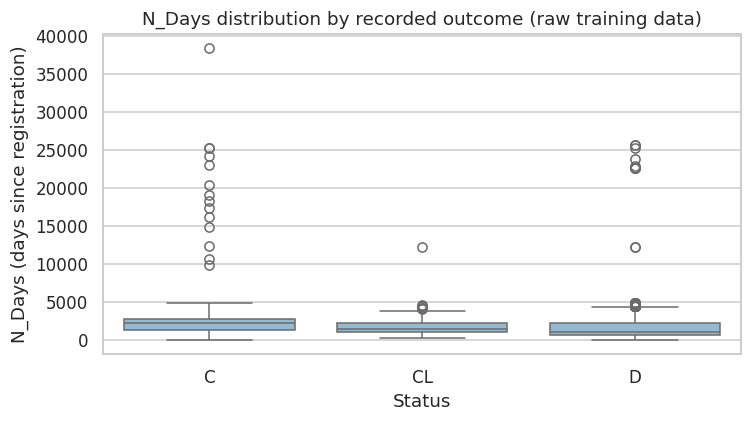

In [5]:
# Leakage probe: N_Days is "time to event" in the source study, so it may encode the label.
ndays = pd.DataFrame(audit["n_days_median_by_status"], index=["median_N_Days"]).T
display(ndays)
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=train, x=config.TARGET, y="N_Days", order=config.CLASS_LABELS, ax=ax)
ax.set_title("N_Days distribution by recorded outcome (raw training data)")
ax.set_ylabel("N_Days (days since registration)")
fig.savefig(paths.FIGURES_DIR / "01_ndays_by_status.png", bbox_inches="tight")
plt.show()

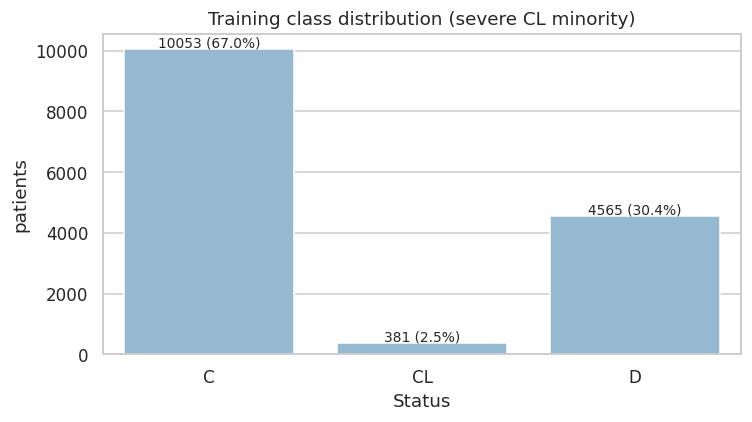

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
counts = train[config.TARGET].value_counts().reindex(config.CLASS_LABELS)
sns.barplot(x=counts.index, y=counts.values, ax=ax)
ax.set_title("Training class distribution (severe CL minority)")
ax.set_ylabel("patients")
for i, v in enumerate(counts):
    ax.text(i, v + 60, f"{v} ({v/len(train):.1%})", ha="center", fontsize=9)
fig.savefig(paths.FIGURES_DIR / "01_class_distribution.png", bbox_inches="tight")
plt.show()

## Interpretation, limitations and decisions

- The train/test schemas match except for the target and identifier; `id` is sequential and
  disjoint between splits, so it carries no transferable signal and will be dropped.
- `Status` contains one `Y` row outside the declared C/CL/D contract — removed in notebook 03
  with an auditable before/after report. Raw files remain untouched.
- Missingness is high (~43–56%) and structured across the same columns; this is preserved as
  an explicit `missing_count` feature and handled by train-only imputation.
- `N_Days` medians differ strongly by class, confirming the leakage concern. Notebook 05 runs a
  with/without ablation; the final decision is evidence-based and documented in metadata.
- CL is only ~2.5% of the data, so stratified CV and calibration are mandatory; accuracy alone
  is a misleading selection metric.